# Week 5 — Improve the first models

In [1]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import CalibrationDisplay

zip_path = "csv.zip"
random_state = 0
max_rows_per_year = 30000
cpu_threads = 2
thresholds = [0.10, 0.20, 0.30, 0.50, 0.70]

with zipfile.ZipFile(zip_path) as z:
    files = {
        Path(name).name: name
        for name in z.namelist()
        if name.lower().endswith(".csv")
    }

numeric_features = [
    "bmi_00",
    "mental_health_days_00",
    "physical_health_days_00"
]

categorical_features = [
    "age_00", "sex_00", "race_00", "marital_status_00", "education_00",
    "income", "gen_health_00", "exercise_00", "smoked_100_cigarettes_00",
    "drinks_alcohol_00", "had_stroke_00", "had_heart_attack_00",
    "had_coronary_heart_disease_00", "cost_barrier_00",
    "l_checkup_00", "has_personal_doctor_00"
]

predictor_columns = numeric_features + categorical_features

target_map = {
    "Diabetic": 1,
    "Non-diabetic": 0,
    "Pre-diabetic": 0
}

In [2]:
annual_frames = []

with zipfile.ZipFile(zip_path) as z:
    for year in range(2005, 2021):
        annual_name = "DATASET_" + str(year) + ".csv"
        with z.open(files[annual_name]) as f:
            raw = pd.read_csv(f, low_memory=False)

        # Records need a known target for supervised learning.
        known_target = raw["diabetes"].notna()
        clean = raw.loc[known_target].copy()
        clean["target"] = clean["diabetes"].map(target_map)
        clean["target"] = clean["target"].astype("int8")

        # This loop uses only 2005-2020, which has the older income column.
        income_source = "income_00"
        maximum_income_code = 8

        original_income = clean[income_source]
        income = pd.to_numeric(original_income, errors="coerce")
        valid_income = income.isin(range(1, maximum_income_code + 1))
        income = income.where(valid_income)
        clean["income"] = income

        # Keep the record, but replace BMI outside the study range with missing.
        bmi_raw = clean["bmi_00"]
        bmi = pd.to_numeric(bmi_raw, errors="coerce")
        valid_bmi = bmi.between(12.00, 99.99)
        clean["bmi_00"] = bmi.where(valid_bmi)

        # Health-day counts must stay between 0 and 30.
        for feature in ["mental_health_days_00", "physical_health_days_00"]:
            original_values = clean[feature]
            values = pd.to_numeric(original_values, errors="coerce")
            clean[feature] = values.where(values.between(0, 30))

        # Keep only the selected predictors, target, and split year.
        clean["year"] = year
        selected_columns = predictor_columns + ["target", "year"]
        clean = clean[selected_columns].copy()

        # Use matching text labels across years; keep missing as its own label.
        for feature in categorical_features:
            labels = clean[feature].astype("string")
            labels = labels.str.replace(r"\.0$", "", regex=True)
            labels = labels.fillna("<missing>")
            clean[feature] = labels.astype(str)

        # Smaller numeric types reduce memory use.
        for feature in numeric_features:
            clean[feature] = clean[feature].astype("float32")

        # Select a reproducible annual sample without balancing the two classes.
        if max_rows_per_year is not None:
            if len(clean) > max_rows_per_year:
                clean, unused_rows = train_test_split(
                    clean,
                    train_size=max_rows_per_year,
                    stratify=clean["target"],
                    random_state=random_state
                )
                del unused_rows

        annual_frames.append(clean)
        print("Prepared", year, "— selected rows:", len(clean))
        del raw, clean

model_data = pd.concat(annual_frames, ignore_index=True)
del annual_frames

Prepared 2005 — selected rows: 30000
Prepared 2006 — selected rows: 30000
Prepared 2007 — selected rows: 30000
Prepared 2008 — selected rows: 30000
Prepared 2009 — selected rows: 30000
Prepared 2010 — selected rows: 30000
Prepared 2011 — selected rows: 30000
Prepared 2012 — selected rows: 30000
Prepared 2013 — selected rows: 30000
Prepared 2014 — selected rows: 30000
Prepared 2015 — selected rows: 30000
Prepared 2016 — selected rows: 30000
Prepared 2017 — selected rows: 30000
Prepared 2018 — selected rows: 30000
Prepared 2019 — selected rows: 30000
Prepared 2020 — selected rows: 30000


In [3]:
# Separate earlier fitting records from later validation records
fit_mask = model_data["year"].between(2005, 2016)
validation_mask = model_data["year"].between(2017, 2020)

X_fit = model_data.loc[fit_mask, predictor_columns].copy()
y_fit = model_data.loc[fit_mask, "target"].copy()
X_validation = model_data.loc[validation_mask, predictor_columns].copy()
y_validation = model_data.loc[validation_mask, "target"].copy()

In [4]:
available_numeric = X_fit[numeric_features].notna().sum()

# Learn a median for each numeric predictor from the fitting data.
numeric_imputer = SimpleImputer(strategy="median")
numeric_scaler = StandardScaler()
numeric_steps = [
    ("imputer", numeric_imputer),
    ("scaler", numeric_scaler)
]
numeric_pipeline = Pipeline(steps=numeric_steps)

# A new category in validation does not stop prediction.
category_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

# Apply numeric steps to numeric columns and encoding to category columns.
transformer_steps = [
    ("numeric", numeric_pipeline, numeric_features),
    ("category", category_encoder, categorical_features)
]
preprocessor = ColumnTransformer(
    transformers=transformer_steps,
    sparse_threshold=1.0
)

# Fit on 2005-2016 only; apply the fitted steps to validation.
X_fit_ready = preprocessor.fit_transform(X_fit)
X_validation_ready = preprocessor.transform(X_validation)
X_fit_ready = X_fit_ready.astype("float32")
X_validation_ready = X_validation_ready.astype("float32")

print("Fitting matrix shape:", X_fit_ready.shape)
print("Validation matrix shape:", X_validation_ready.shape)
print("Encoded columns:", len(preprocessor.get_feature_names_out()))

Fitting matrix shape: (360000, 89)
Validation matrix shape: (120000, 89)
Encoded columns: 89


## Baseline models


In [5]:
fitted_models = {}
validation_probabilities = {}

lr_baseline = LogisticRegression(
    max_iter=1000,
    solver="lbfgs",
    random_state=random_state
)
lr_baseline.fit(X_fit_ready, y_fit)
lr_prediction = lr_baseline.predict_proba(X_validation_ready)
fitted_models["LR baseline"] = lr_baseline
validation_probabilities["LR baseline"] = lr_prediction[:, 1]
print("Logistic Regression baseline finished.")
print("Iterations used:", lr_baseline.n_iter_)

Logistic Regression baseline finished.
Iterations used: [42]


In [6]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=20,
    n_jobs=cpu_threads,
    random_state=random_state
)
rf_baseline.fit(X_fit_ready, y_fit)
rf_prediction = rf_baseline.predict_proba(X_validation_ready)
fitted_models["RF baseline"] = rf_baseline
validation_probabilities["RF baseline"] = rf_prediction[:, 1]
print("Random Forest baseline finished.")

Random Forest baseline finished.


In [7]:
xgb_baseline = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=1.0,
    colsample_bytree=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    n_jobs=cpu_threads,
    random_state=random_state
)
xgb_baseline.fit(X_fit_ready, y_fit)
xgb_prediction = xgb_baseline.predict_proba(X_validation_ready)
fitted_models["XGB baseline"] = xgb_baseline
validation_probabilities["XGB baseline"] = xgb_prediction[:, 1]
print("XGBoost baseline finished.")

XGBoost baseline finished.


## Try class weighting
There are fewer diabetic records than non-diabetic records. Class weighting gives diabetic records more weight during training. These are class weights, not BRFSS survey weights.

LR and RF use `class_weight="balanced"`. XGBoost uses the number of negative records divided by positive records in the fitting data.

In [8]:
# clone makes an unfitted copy with the same starting settings
lr_weighted = clone(lr_baseline)
lr_weighted.set_params(class_weight="balanced")

# Fit the weighted copy and keep its validation scores
lr_weighted.fit(X_fit_ready, y_fit)
lr_weighted_prediction = lr_weighted.predict_proba(X_validation_ready)
fitted_models["LR weighted"] = lr_weighted
validation_probabilities["LR weighted"] = lr_weighted_prediction[:, 1]
print("Weighted Logistic Regression finished.")
print("Iterations used:", lr_weighted.n_iter_)

Weighted Logistic Regression finished.
Iterations used: [57]


In [9]:
# Copy the RF settings and give more weight to the smaller class
rf_weighted = clone(rf_baseline)
rf_weighted.set_params(class_weight="balanced")
rf_weighted.fit(X_fit_ready, y_fit)
rf_weighted_prediction = rf_weighted.predict_proba(X_validation_ready)
fitted_models["RF weighted"] = rf_weighted
validation_probabilities["RF weighted"] = rf_weighted_prediction[:, 1]
print("Weighted Random Forest finished.")

Weighted Random Forest finished.


In [10]:
# Calculate the class ratio using fitting labels only
fit_negative_n = int(y_fit.eq(0).sum())
fit_positive_n = int(y_fit.eq(1).sum())
positive_class_weight = fit_negative_n / fit_positive_n
print("XGBoost positive-class weight:", round(positive_class_weight, 3))

# Apply this ratio to a copy of XGBoost
xgb_weighted = clone(xgb_baseline)
xgb_weighted.set_params(scale_pos_weight=positive_class_weight)
xgb_weighted.fit(X_fit_ready, y_fit)
xgb_weighted_prediction = xgb_weighted.predict_proba(X_validation_ready)
fitted_models["XGB weighted"] = xgb_weighted
validation_probabilities["XGB weighted"] = xgb_weighted_prediction[:, 1]
print("Weighted XGBoost finished.")

XGBoost positive-class weight: 7.288
Weighted XGBoost finished.


## Compare five thresholds
A threshold turns a model score into a prediction. A lower threshold can find more diabetic records, but it can also give more false positives. I try five thresholds for each of the six model versions.


In [11]:
# List the three model families and their two versions
model_info = pd.DataFrame({
    "configuration": ["LR baseline", "RF baseline", "XGB baseline",
                      "LR weighted", "RF weighted", "XGB weighted"],
    "family": ["Logistic Regression", "Random Forest", "XGBoost",
               "Logistic Regression", "Random Forest", "XGBoost"],
    "weighting": ["none", "none", "none", "balanced", "balanced", "balanced"]
})

result_rows = []
for _, info in model_info.iterrows():
    name = info["configuration"]
    probability = validation_probabilities[name]

    # Ranking metrics do not depend on the classification threshold
    roc_auc = roc_auc_score(y_validation, probability)
    curve_precision, curve_recall, curve_thresholds = precision_recall_curve(
        y_validation, probability
    )
    pr_auc = auc(curve_recall, curve_precision)

    # Try each threshold using the same scores
    for threshold in thresholds:
        predicted = probability >= threshold
        precision = precision_score(y_validation, predicted, zero_division=0)
        recall = recall_score(y_validation, predicted, zero_division=0)
        f1 = f1_score(y_validation, predicted, zero_division=0)

        # Keep one result row for this model version and threshold
        result_rows.append({
            "configuration": name,
            "family": info["family"],
            "weighting": info["weighting"],
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc
        })

threshold_results = pd.DataFrame(result_rows)
print("Six versions at the same 0.50 threshold:")
results_at_half = threshold_results[threshold_results["threshold"].eq(0.50)]
display(results_at_half.round(4))
print("Every weighting/threshold trial:")
display(threshold_results.round(4))

Six versions at the same 0.50 threshold:


,configuration,family,weighting,threshold,precision,recall,f1,roc_auc,pr_auc
3,LR baseline,Logistic Regression,none,0.5,0.5647,0.1301,0.2115,0.8228,0.4050
8,RF baseline,Random Forest,none,0.5,0.6652,0.0273,0.0525,0.8126,0.3982
13,XGB baseline,XGBoost,none,0.5,0.6050,0.0857,0.1501,0.8249,0.4146
18,LR weighted,Logistic Regression,balanced,0.5,0.2963,0.7833,0.4300,0.8229,0.4036
23,RF weighted,Random Forest,balanced,0.5,0.2935,0.7719,0.4253,0.8162,0.3996
28,XGB weighted,XGBoost,balanced,0.5,0.2925,0.8000,0.4284,0.8251,0.4148


Every weighting/threshold trial:


,configuration,family,weighting,threshold,precision,recall,f1,roc_auc,pr_auc
0,LR baseline,Logistic Regression,none,0.1,0.2746,0.8424,0.4142,0.8228,0.4050
1,LR baseline,Logistic Regression,none,0.2,0.3643,0.5971,0.4525,0.8228,0.4050
2,LR baseline,Logistic Regression,none,0.3,0.4397,0.3884,0.4125,0.8228,0.4050
3,LR baseline,Logistic Regression,none,0.5,0.5647,0.1301,0.2115,0.8228,0.4050
4,LR baseline,Logistic Regression,none,0.7,0.6481,0.0293,0.0561,0.8228,0.4050
5,RF baseline,Random Forest,none,0.1,0.2519,0.8616,0.3899,0.8126,0.3982
6,RF baseline,Random Forest,none,0.2,0.3695,0.5424,0.4396,0.8126,0.3982
7,RF baseline,Random Forest,none,0.3,0.4829,0.2595,0.3376,0.8126,0.3982
8,RF baseline,Random Forest,none,0.5,0.6652,0.0273,0.0525,0.8126,0.3982
9,RF baseline,Random Forest,none,0.7,0.0000,0.0000,0.0000,0.8126,0.3982


## Choose settings for each model
I choose the version and threshold with the highest validation F1 for each model family. If F1 is tied, I use higher precision, then the higher threshold.

At threshold 0.50, class weighting increased recall from 0.027–0.130 to 0.772–0.800. However, precision dropped to about 0.29. ROC-AUC and PR-AUC changed very little. Weighting helped find more diabetic records at this threshold, but did not greatly improve how the models ranked records.


In [12]:
# Sorting puts the preferred result first
# stable sorting keeps ties reproducible
ranked_results = threshold_results.sort_values(
    ["f1", "precision", "threshold"],
    ascending=[False, False, False],
    kind="stable"
)

# After sorting, keep the first (best) row for each family
selected_settings = ranked_results.drop_duplicates("family")
selected_settings = selected_settings.sort_values("family").reset_index(drop=True)

print("One selected version and threshold for each family:")
display(selected_settings.round(4))

# Show the choice alongside this run's baseline at 0.50.
baseline_names = ["LR baseline", "RF baseline", "XGB baseline"]
baseline_mask = results_at_half["configuration"].isin(baseline_names)
baseline_comparison = results_at_half.loc[baseline_mask].copy()
baseline_comparison["stage"] = "Baseline at 0.50"
chosen_comparison = selected_settings.copy()
chosen_comparison["stage"] = "Selected on validation"
comparison = pd.concat([baseline_comparison, chosen_comparison], ignore_index=True)
print("Baseline versus selected settings — same validation period:")
display(comparison.round(4))

One selected version and threshold for each family:


,configuration,family,weighting,threshold,precision,recall,f1,roc_auc,pr_auc
0,LR baseline,Logistic Regression,none,0.2,0.3643,0.5971,0.4525,0.8228,0.4050
1,RF baseline,Random Forest,none,0.2,0.3695,0.5424,0.4396,0.8126,0.3982
2,XGB baseline,XGBoost,none,0.2,0.3634,0.6078,0.4548,0.8249,0.4146


Baseline versus selected settings — same validation period:


,configuration,family,weighting,threshold,precision,recall,f1,roc_auc,pr_auc,stage
0,LR baseline,Logistic Regression,none,0.5,0.5647,0.1301,0.2115,0.8228,0.4050,Baseline at 0.50
1,RF baseline,Random Forest,none,0.5,0.6652,0.0273,0.0525,0.8126,0.3982,Baseline at 0.50
2,XGB baseline,XGBoost,none,0.5,0.6050,0.0857,0.1501,0.8249,0.4146,Baseline at 0.50
3,LR baseline,Logistic Regression,none,0.2,0.3643,0.5971,0.4525,0.8228,0.4050,Selected on validation
4,RF baseline,Random Forest,none,0.2,0.3695,0.5424,0.4396,0.8126,0.3982,Selected on validation
5,XGB baseline,XGBoost,none,0.2,0.3634,0.6078,0.4548,0.8249,0.4146,Selected on validation


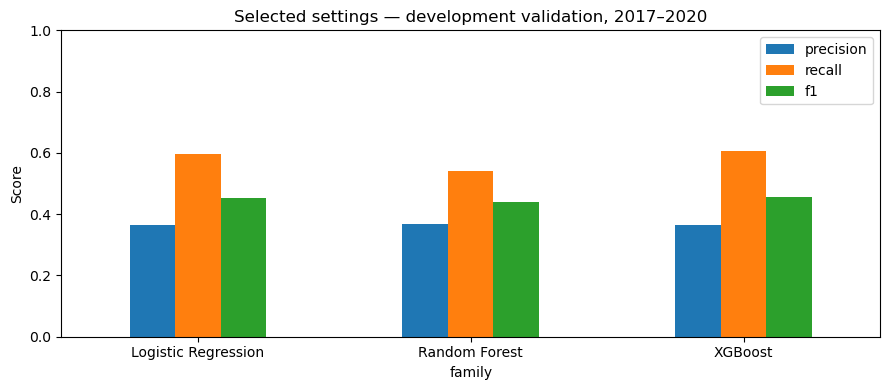

In [13]:
# Compare the selected family results without hiding the precision/recall tradeoff
plot_scores = selected_settings.set_index("family")
plot_scores[["precision", "recall", "f1"]].plot(kind="bar", figsize=(9, 4))
plt.title("Selected settings — development validation, 2017–2020")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Check prediction errors and probability scores
**Selected settings:** All three families selected their unweighted baseline version at threshold **0.20**. This was the best option among the settings tried here.

| Model | Precision | Recall | F1 at 0.20 | F1 at 0.50 |
| --- | --- | --- | --- | --- |
| Logistic Regression | 0.3643 | 0.5971 | 0.4525 | 0.2115 |
| Random Forest | 0.3695 | 0.5424 | 0.4396 | 0.0525 |
| XGBoost | 0.3634 | 0.6078 | 0.4548 | 0.1501 |

Lowering the threshold increased recall and F1, but reduced precision. XGBoost had a slightly higher validation F1 than the other models. The difference is small, so I still need future-year results before making a final comparison.

The confusion matrices show correct predictions and errors at the selected thresholds. The calibration plot compares the model scores with the observed proportion of diabetic records. Points near the diagonal show closer agreement.


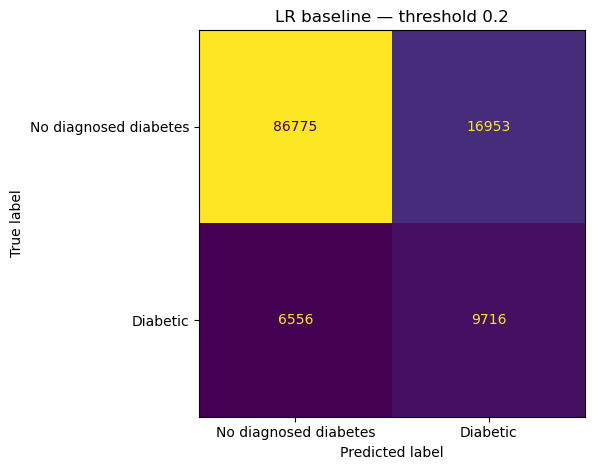

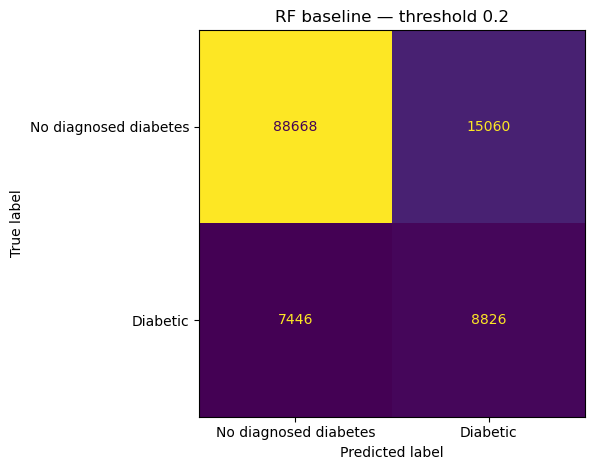

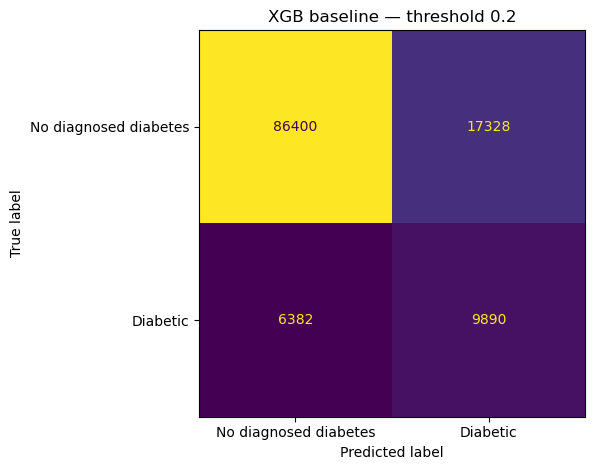

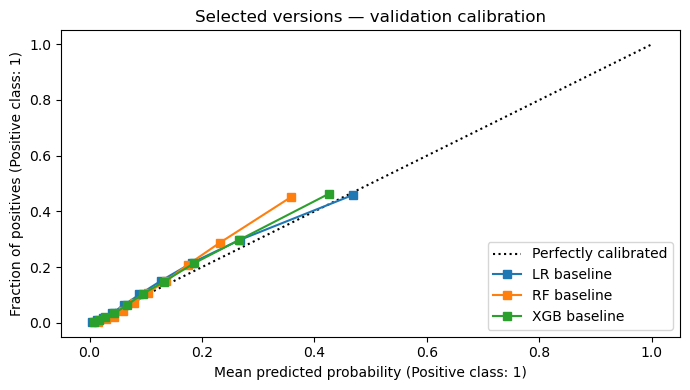

In [14]:
for _, choice in selected_settings.iterrows():
    name = choice["configuration"]
    threshold = choice["threshold"]
    probability = validation_probabilities[name]
    predicted = probability >= threshold

    ConfusionMatrixDisplay.from_predictions(
        y_validation,
        predicted,
        labels=[0, 1],
        display_labels=["No diagnosed diabetes", "Diabetic"],
        values_format="d",
        colorbar=False
    )
    plt.title(name + " — threshold " + str(threshold))
    plt.tight_layout()
    plt.show()

figure, calibration_axis = plt.subplots(figsize=(7, 4))
for _, choice in selected_settings.iterrows():
    name = choice["configuration"]
    probability = validation_probabilities[name]
    CalibrationDisplay.from_predictions(
        y_validation,
        probability,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=calibration_axis
    )
calibration_axis.set_title("Selected versions — validation calibration")
plt.tight_layout()
plt.show()

At threshold 0.20, XGBoost correctly identified 9,890 of the 16,272 diabetic validation records. It missed 6,382 and produced 17,328 false positives. This shows the tradeoff behind its higher recall.

For the selected unweighted models, many calibration points are near the diagonal, with some differences at higher scores.

## 11. Refit the seleceted models on 2005-2020
I now keep the selected settings fixed and fit preprocessing and all three models again using the selected 2005–2020 records.


In [15]:
# Release earlier matrices and copies before the larger refit.
del X_fit_ready, X_validation_ready, X_fit, X_validation

X_full = model_data[predictor_columns]
y_full = model_data["target"]
final_preprocessor = clone(preprocessor)
X_full_ready = final_preprocessor.fit_transform(X_full)
X_full_ready = X_full_ready.astype("float32")

full_negative_n = int(y_full.eq(0).sum())
full_positive_n = int(y_full.eq(1).sum())
full_positive_weight = full_negative_n / full_positive_n

final_models = {}
final_thresholds = {}
final_rows = []

for _, choice in selected_settings.iterrows():
    family = choice["family"]
    name = choice["configuration"]
    final_model = clone(fitted_models[name])

    if family == "XGBoost" and choice["weighting"] == "balanced":
        final_model.set_params(scale_pos_weight=full_positive_weight)

    print("Refitting", name, "on", len(y_full), "selected records...")
    final_model.fit(X_full_ready, y_full)
    final_models[family] = final_model
    final_thresholds[family] = float(choice["threshold"])
    final_rows.append({
        "family": family,
        "configuration": name,
        "threshold": choice["threshold"],
        "training_years": "2005–2020",
        "selected_rows": len(y_full)
    })

final_summary = pd.DataFrame(final_rows)
display(final_summary)

Refitting LR baseline on 480000 selected records...
Refitting RF baseline on 480000 selected records...
Refitting XGB baseline on 480000 selected records...


,family,configuration,threshold,training_years,selected_rows
0,Logistic Regression,LR baseline,0.2,2005–2020,480000
1,Random Forest,RF baseline,0.2,2005–2020,480000
2,XGBoost,XGB baseline,0.2,2005–2020,480000


## Prepare the 2021-2024 inputs
All three models finished fitting on 480,000 selected records from 2005–2020. Each keeps threshold 0.20.

Next, I load only the future predictor columns. I combine income codes 8–11 into the common top group, apply the same BMI and health-day checks, and use `final_preprocessor.transform`.


In [16]:
# These names deliberately exclude the diabetes target
future_source_columns = list(predictor_columns)
future_source_columns.remove("income")
future_source_columns.append("income_01")

future_inputs = {}
future_rows = []

with zipfile.ZipFile(zip_path) as z:
    for year in range(2021, 2025):
        annual_name = "DATASET_" + str(year) + ".csv"
        with z.open(files[annual_name]) as f:
            future = pd.read_csv(
                f,
                usecols=future_source_columns,
                low_memory=False
            )

        # Match the newer income codes to the training income groups
        income_raw = future["income_01"]
        income = pd.to_numeric(income_raw, errors="coerce")
        income_conversion = income_raw.notna() & income.isna()
        valid_income = income.isin(range(1, 12))
        invalid_income = income.notna() & ~valid_income
        income = income.where(valid_income)
        future["income"] = income.replace({9: 8, 10: 8, 11: 8})

        # Change BMI values outside the chosen range to missing values
        bmi_raw = future["bmi_00"]
        bmi = pd.to_numeric(bmi_raw, errors="coerce")
        bmi_conversion = bmi_raw.notna() & bmi.isna()
        valid_bmi = bmi.between(12.00, 99.99)
        invalid_bmi = bmi.notna() & ~valid_bmi
        future["bmi_00"] = bmi.where(valid_bmi)

        # Keep valid health-day values from 0 to 30 and count cleaning changes
        health_changes = 0
        health_conversions = 0
        for feature in ["mental_health_days_00", "physical_health_days_00"]:
            original_values = future[feature]
            values = pd.to_numeric(original_values, errors="coerce")
            conversion_failed = original_values.notna() & values.isna()
            invalid_days = values.notna() & ~values.between(0, 30)
            health_conversions += int(conversion_failed.sum())
            health_changes += int(invalid_days.sum())
            future[feature] = values.where(values.between(0, 30))

        # Use the same category labels and numeric types as the training data
        for feature in categorical_features:
            labels = future[feature].astype("string")
            labels = labels.str.replace(r"\.0$", "", regex=True)
            labels = labels.fillna("<missing>")
            future[feature] = labels.astype(str)

        for feature in numeric_features:
            future[feature] = future[feature].astype("float32")

        # Apply the fitted preprocessing
        X_future = future[predictor_columns]
        X_future_ready = final_preprocessor.transform(X_future)
        X_future_ready = X_future_ready.astype("float32")
        future_inputs[year] = X_future_ready
        future_rows.append({
            "year": year,
            "predictor_records": len(future),
            "encoded_columns": X_future_ready.shape[1],
            "income_conversion_failures": int(income_conversion.sum()),
            "invalid_income_to_missing": int(invalid_income.sum()),
            "bmi_conversion_failures": int(bmi_conversion.sum()),
            "bmi_range_to_missing": int(invalid_bmi.sum()),
            "health_conversion_failures": health_conversions,
            "health_values_to_missing": health_changes
        })
        print("Prepared future predictors for", year)
        del future, X_future, X_future_ready

future_summary = pd.DataFrame(future_rows)
display(future_summary)

Prepared future predictors for 2021
Prepared future predictors for 2022
Prepared future predictors for 2023
Prepared future predictors for 2024


,year,predictor_records,encoded_columns,income_conversion_failures,invalid_income_to_missing,bmi_conversion_failures,bmi_range_to_missing,health_conversion_failures,health_values_to_missing
0,2021,437250,89,0,0,0,115,0,0
1,2022,442670,89,0,0,0,178,0,0
2,2023,431746,89,0,0,0,187,0,0
3,2024,454774,89,0,0,0,209,0,0
